PROJETO FINAL

1. Importação das bibliotecas:

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



2. Importação do arquivo de banco de dados "vendas.csv".


a) importação o arquivo "vendas.csv", utilizando a formatação 'utf-8' e troca-se a separação das colunas por ";"

In [5]:
df_vendas = pd.read_csv("vendas.csv", encoding="utf-8", sep=";")


3. Obteção das infomações básicas e tratamento do banco de dados


a) Na coluna "cidade_cliente" há espaços sem informação. Utilizamos o ".fillna" substituindo esses espaços por "Não informado"



b) Em seguinda é importante formatarmos as informações da coluna "data_venda" para o formato datetime. Verifica-se as datas inválidas e faz-se o tratamento com ".isna()". Verifica-se que apenas na coluna "data_venda" ficamos com espaços "Non-Null", pois considera-se melhor deixar sem dados do que preencher com informações aleatórias.

c) Trata-se a "categoria_produto" para evitar duplicidades em virtude de acentuação nas palavras "Informática" e "Eletrônicos"

d) Por último, utilizamos o ".info()" para obtermos as informações do banco de dados.

In [15]:
df_vendas["cidade_cliente"] = df_vendas["cidade_cliente"].fillna(
    "Não informado"
)


df_vendas["data_venda"] = pd.to_datetime(
df_vendas["data_venda"], errors="coerce"
)
datas_invalidas = df_vendas["data_venda"].isna().sum()

df_vendas["categoria_produto"] = df_vendas["categoria_produto"].replace({
    "Informatica": "Informática",
    "Eletronicos": "Eletrônicos"
})

print(df_vendas.info())

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id_item_venda      50000 non-null  int64         
 1   id_pedido          50000 non-null  int64         
 2   data_venda         49851 non-null  datetime64[us]
 3   nome_produto       50000 non-null  str           
 4   categoria_produto  50000 non-null  str           
 5   quantidade         50000 non-null  int64         
 6   preco_unitario     50000 non-null  float64       
 7   desconto           50000 non-null  float64       
 8   valor_total        50000 non-null  float64       
 9   nome_cliente       50000 non-null  str           
 10  cidade_cliente     50000 non-null  str           
 11  estado_cliente     50000 non-null  str           
 12  nome_vendedor      50000 non-null  str           
 13  forma_pagamento    50000 non-null  str           
 14  status_venda     

4. Cálculo do faturamento total bruto e do faturamento líquido

a) O faturamento bruto pode ser definido pela preço unitário x a quantidade vendida. Para o faturamento total bruto, utilizou-se ".sum()" para fazer a soma total de todo o faturamento bruto.

b) O faturamento líquido é o definido pelo faturamento bruto - o desconto. A coluna "valor_total" já representa o faturamento líquido. Para o faturamento total líquido utilizou-se o ".sum()" para fazer a oma total de todo o faturamento líquido.

c) O desconto total pode ser obtido pela subtração do faturamento total bruto menos o faturalmento total líquido.

In [16]:
faturamento_total_bruto = ((df_vendas['preco_unitario']) * (df_vendas['quantidade'])).sum()
print(f"O faturamento total bruto foi de: R$ {faturamento_total_bruto:.2f}")

faturamento_total_liquido = ((df_vendas['valor_total']).sum())
print(f"O valor total liquido foi de: R$ {faturamento_total_liquido:.2f}")

desconto_total = (faturamento_total_bruto - faturamento_total_liquido)
print(f"O desconto total foi de: R$ {desconto_total:.2f}")

O faturamento total bruto foi de: R$ 138181932.60
O valor total liquido foi de: R$ 129874945.21
O desconto total foi de: R$ 8306987.39


5. Cálculo do volume de vendas

a) Considerando o volume de vendas de um produto como sendo a quantidade vendida, agrupamos a lista de produtos ("nome_produto") considerando a quantidade. Para tanto, utilizamos ".count()" para contagem, ".sort_values(ascending=False)" para ordenar a lista em formato decrescente e ".head(10) para listar apenas os 10 primeiro produtos

In [26]:
volume_de_vendas = df_vendas.groupby("nome_produto")["quantidade"].count().sort_values(ascending=False).head(10)
print(volume_de_vendas)




nome_produto
Teclado Mecânico RGB        3415
Tablet 10"                  3409
Smart TV 55" 4K             3369
Monitor 24" Full HD         3366
Monitor 27" 4K              3362
Caixa de Som Portátil       3355
Fone de Ouvido Bluetooth    3345
Smartwatch Fit Z            3332
Mouse Gamer 10k DPI         3331
Carregador Super Rápido     3321
Name: quantidade, dtype: int64


6. Desempenho por categoria

categoria_produto
Informática    69682587.67
Eletrônicos    51478354.48
Acessórios      5261809.23
Áudio           3452193.83
Name: valor_total, dtype: float64
A categoria de produto com maior faturamento foi Informática com R$ 69682587.67


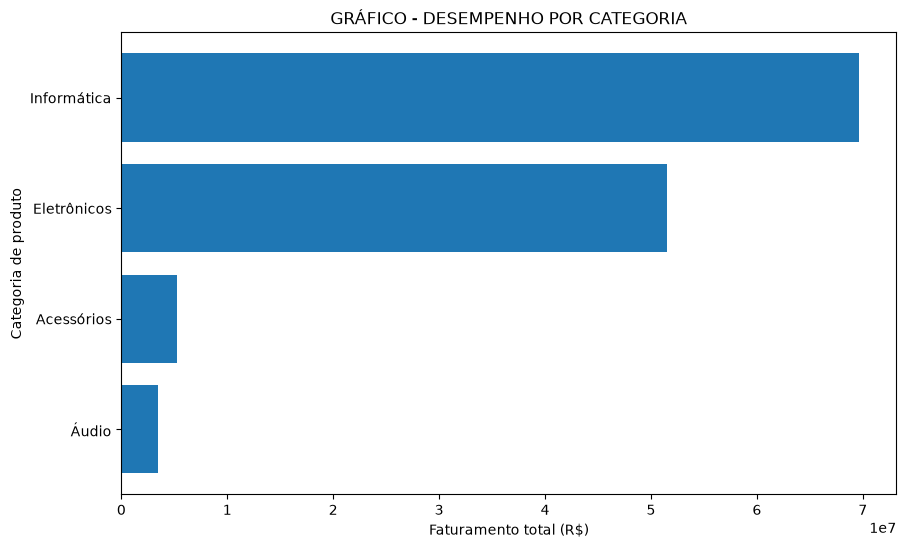

In [31]:
desempenho_por_categoria = df_vendas.groupby("categoria_produto")["valor_total"].sum().sort_values(ascending=False).head(10)

categoria_mais_venda = desempenho_por_categoria.idxmax()
maior_valor_categoria = desempenho_por_categoria.max()

print(desempenho_por_categoria)
print(f"A categoria de produto com maior faturamento foi {categoria_mais_venda} com R$ {maior_valor_categoria:.2f}")


plt.figure(figsize=(10, 6))

plt.barh(
    desempenho_por_categoria.index,
    desempenho_por_categoria.values
)

plt.xlabel("Faturamento total (R$)")
plt.ylabel("Categoria de produto")
plt.title("GRÁFICO - DESEMPENHO POR CATEGORIA")

# Faz a maior categoria aparecer no topo
plt.gca().invert_yaxis()

plt.show()



7. Sazonalidade e evolução

In [19]:
vendas_por_ano = (
    df_vendas.groupby(df_vendas["data_venda"].dt.year)["id_item_venda"]
    .count()
    .sort_values(ascending=False)
)

print("Vendas por ano:")
print(vendas_por_ano)

# Ano com maior volume de vendas
maior_ano = vendas_por_ano.idxmax()
quantidade_ano = vendas_por_ano.max()
menor_ano = vendas_por_ano.idxmin()
quantidade_menor_ano = vendas_por_ano.min()

print(
    f"\nO ano com maior volume de vendas foi {maior_ano}, "
    f"com {quantidade_ano} vendas."
)
print(
    f"\nO ano com menor volume de vendas foi {menor_ano}, "
    f"com {quantidade_menor_ano} vendas."
)

vendas_por_mes = (
    df_vendas.groupby(df_vendas["data_venda"].dt.month)["id_item_venda"]
    .count()
    .sort_values(ascending=False)
)

print("\nVendas por mês:")
print(vendas_por_mes)


maior_mes = vendas_por_mes.idxmax()
quantidade_mes = vendas_por_mes.max()
menor_mes = vendas_por_mes.idxmin()
quantidade_menor_mes = vendas_por_mes.min()



print(
    f"\nO mês com maior volume de vendas foi o mês {maior_mes}, "
    f"com {quantidade_mes} vendas."
)
print(
    f"\nO mês com menor volume de vendas foi o mês {menor_mes}, "
    f"com {quantidade_menor_mes} vendas."
)

Vendas por ano:
data_venda
2021.0    16739
2023.0    16674
2022.0    16438
Name: id_item_venda, dtype: int64

O ano com maior volume de vendas foi 2021.0, com 16739 vendas.

O ano com menor volume de vendas foi 2022.0, com 16438 vendas.

Vendas por mês:
data_venda
11.0    5036
12.0    4966
10.0    4243
1.0     4192
8.0     4138
5.0     4087
7.0     4084
6.0     3915
9.0     3913
3.0     3907
4.0     3838
2.0     3532
Name: id_item_venda, dtype: int64

O mês com maior volume de vendas foi o mês 11.0, com 5036 vendas.

O mês com menor volume de vendas foi o mês 2.0, com 3532 vendas.


8. Avaliação de Equipe

In [20]:
melhores_vendedores = df_vendas.groupby(df_vendas["nome_vendedor"])["valor_total"].sum().sort_values(ascending=False).head(5)
print(melhores_vendedores)

ticket_vendedores = df_vendas.groupby(df_vendas["nome_vendedor"])["quantidade"].sum().sort_values(ascending=False)
print(ticket_vendedores)


ticket_medio_vendedor = (
    df_vendas.groupby("nome_vendedor")[["valor_total", "quantidade"]]
    .sum()
)

ticket_medio_vendedor["ticket_medio"] = (
    ticket_medio_vendedor["valor_total"]
    / ticket_medio_vendedor["quantidade"]
)

ticket_medio_vendedor = ticket_medio_vendedor.sort_values(
    by="ticket_medio",
    ascending=False
)

print(ticket_medio_vendedor)



nome_vendedor
Carlos Eduardo    9361532.83
Otávio Borges     9146223.29
Fernanda Alves    9096769.89
Julia Martins     8756470.41
Diana Souza       8734464.50
Name: valor_total, dtype: float64
nome_vendedor
Carlos Eduardo    5203
Julia Martins     5168
Kauan Vieira      5057
Larissa Mendes    5044
Fernanda Alves    5042
Gabriel Gomes     4994
Marcos Paulo      4984
Otávio Borges     4965
Ana Silva         4927
Diana Souza       4904
Helena Rocha      4874
Bruno Costa       4843
Eduardo Lima      4798
Natália Pires     4780
Igor Santos       4680
Name: quantidade, dtype: int64
                valor_total  quantidade  ticket_medio
nome_vendedor                                        
Otávio Borges    9146223.29        4965   1842.139635
Eduardo Lima     8670671.17        4798   1807.142803
Fernanda Alves   9096769.89        5042   1804.198709
Carlos Eduardo   9361532.83        5203   1799.256742
Diana Souza      8734464.50        4904   1781.089825
Igor Santos      8188048.40        4680

9. Preferências de pagamento

In [21]:
formas_pagamento = df_vendas.groupby(df_vendas["forma_pagamento"])["id_item_venda"].count().sort_values(ascending=False)
print(formas_pagamento)

formas_pagamento_percentual = (
    formas_pagamento / formas_pagamento.sum() * 100
).sort_values(ascending=False)

print(formas_pagamento_percentual
      .round(2)
      .astype(str) + "%")

forma_pagamento
Cartão de Crédito    12762
Boleto               12569
PIX                  12547
Cartão de Débito     12122
Name: id_item_venda, dtype: int64
forma_pagamento
Cartão de Crédito    25.52%
Boleto               25.14%
PIX                  25.09%
Cartão de Débito     24.24%
Name: id_item_venda, dtype: str


10. Análise Geográfica

In [22]:
regioes = df_vendas.groupby(df_vendas["estado_cliente"])["valor_total"].sum().sort_values(ascending=False)
print(regioes)

regioes_percentual = (
    regioes / regioes.sum() * 100
).sort_values(ascending=False)

print(regioes_percentual
      .round(2)
      .astype(str) + "%")

estado_cliente
SC    13334630.64
PR    13312024.67
RJ    13229561.17
BA    13070198.38
DF    13034637.13
GO    12956132.40
MG    12928191.94
SP    12904323.43
PE    12904261.75
RS    12200983.70
Name: valor_total, dtype: float64
estado_cliente
SC    10.27%
PR    10.25%
RJ    10.19%
BA    10.06%
DF    10.04%
GO     9.98%
MG     9.95%
SP     9.94%
PE     9.94%
RS     9.39%
Name: valor_total, dtype: str
